# 01 · Exploring LEDGAR — project checkpoint m1

*Estimated runtime: about 1 minute on the Mac (CPU); a few seconds with `FAST_RUN=1`.*

Before training anything, we look at the data the classifier will meet: how many clauses per type, how
long they are, whether the splits overlap, and how low the floor is. Lengths and every choice derived here
come from the **training** split only; the validation and test splits are read only for their class
counts and for exact-duplicate checks, never to tune anything.

At the end of the notebook you have:
- the class distribution (`reports/figures/class_distribution.png`, `reports/class_counts.csv`);
- the length study that fixes `max_length` (DistilBERT) and `max_words` (LSTM);
- the overlap between splits, and the clauses that carry two different labels;
- the lazy floor, first row of the results table (`results/lazy/`).

Parts: **A** classes · **B** lengths · **C** duplicates and label conflicts · **D** reading close types · **E** the lazy floor.

## Imports

- `numpy`, `pandas`: arrays and tables.
- `transformers`: the DistilBERT tokenizer, to count the tokens the model will really see.
- `ledgar`: the project package. `config` holds every constant, `data` loads LEDGAR and computes the
  statistics, `metrics` the scores, `plots` the figures, `runs` writes the artefacts of a run to `results/`.

In [1]:
import json
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")  # progress bars without ipywidgets

import numpy as np
import pandas as pd
import transformers
from huggingface_hub.utils import logging as hub_logging
from transformers import AutoTokenizer

from ledgar import data, metrics, plots, runs
from ledgar.config import Config, set_seed

transformers.logging.set_verbosity_error()  # hide the long loading reports
hub_logging.set_verbosity_error()
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 100)

## Constants

`Config.from_env()` reads `FAST_RUN`, `SEED` and `DEVICE` from the environment; every other value is a default
of `src/ledgar/config.py`. With `FAST_RUN=1` each split is reduced to a per-class subset (at most 30 training
and 5 evaluation clauses per type) and all outputs go to `.fast/`, so the committed figures and results are
never overwritten by a quick check.

In [2]:
cfg = Config.from_env()
set_seed(cfg.seed)
FIGURES = cfg.path(cfg.reports_dir, "figures")
print(cfg)

fast_run=False | seed=0 | device=mps | model_name=distilbert-base-uncased | max_length=512 | max_words=476 | epochs=3


## Helper cell: the data (run this cell, no need to modify it)

`load_ledgar` downloads LEDGAR once (about 60 MB) at the dataset revision pinned in `Config`, and adds an
`index` column: the position of each clause in its official split. It travels with every saved
prediction, so a result can always be joined back to the text of the clause.

In [3]:
ledgar = data.load_ledgar(cfg)
LABELS = data.label_names(ledgar)
train_texts, train_labels = ledgar["train"]["text"], np.array(ledgar["train"]["label"])
print({split: ledgar[split].num_rows for split in ledgar}, "|", len(LABELS), "clause types")
print("example:", LABELS[train_labels[0]], "|", train_texts[0][:200], "...")

{'train': 60000, 'validation': 10000, 'test': 10000} | 100 clause types
example: Waivers | Except as otherwise set forth in this Debenture, the Company, for itself and its legal representatives, successors and assigns, expressly waives presentment, protest, demand, notice of dishonor, notic ...


# Part A: how many clauses per type?

S01 p14: "In the project (100 clause types, very imbalanced), report macro-F1." Here is how imbalanced:
clauses per type in each split, sorted by training count, on a log scale.

n_classes                       100.0
largest                        3167.0
smallest                         23.0
imbalance_ratio                 137.7
mean_per_class                  600.0
classes_below_1pct               71.0
train_classes_below_100           3.0
train_classes_below_300          22.0
train_classes_below_10            0.0
train_classes_missing             0.0
validation_classes_below_10       3.0
validation_classes_missing        1.0
test_classes_below_10             3.0
test_classes_missing              0.0
dtype: float64

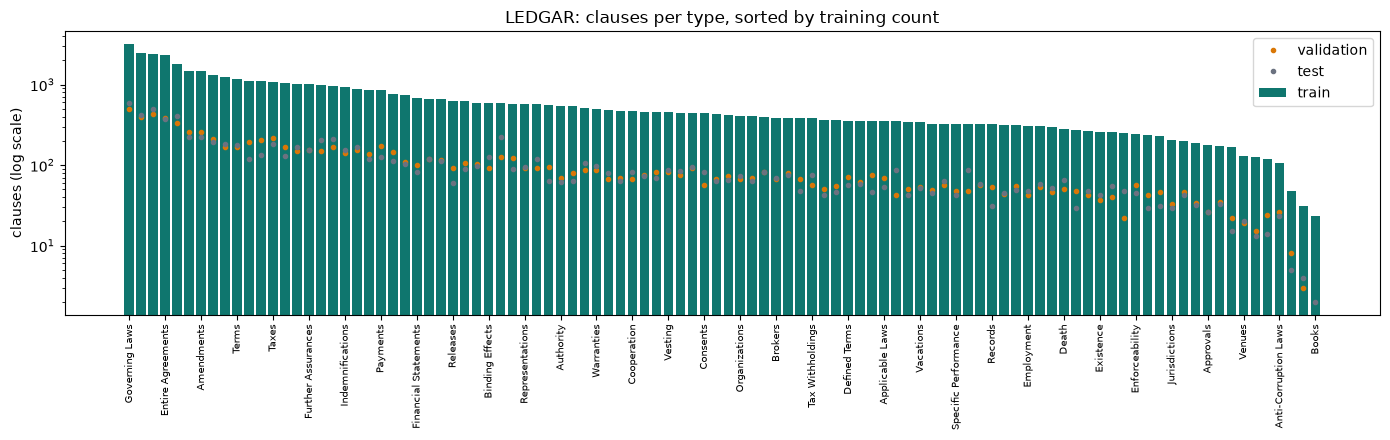

In [4]:
counts = data.class_counts(ledgar, cfg.n_classes).set_axis(LABELS)
class_stats = data.class_stats(counts)
fig = plots.plot_class_distribution(counts, LABELS, path=FIGURES / "class_distribution.png")
pd.Series(class_stats).round(1)

The thinnest types, in any split (fewer than 100 training clauses, or fewer than 10 validation or test clauses):

In [5]:
counts[(counts["train"] < 100) | (counts["validation"] < 10) | (counts["test"] < 10)].sort_values("train")

,train,validation,test
Books,23,0,2
Assigns,31,3,4
Qualifications,47,8,5


In [6]:
assert len(LABELS) == 100 and LABELS == sorted(LABELS), "100 clause types, in alphabetical order"
assert (counts["train"] > 0).all(), "every clause type has training examples"
if not cfg.fast_run:
    assert [ledgar[s].num_rows for s in data.SPLITS] == [60_000, 10_000, 10_000], "official LexGLUE sizes"
    assert (class_stats["largest"], class_stats["smallest"]) == (3167, 23), "Governing Laws 3 167, Books 23"
    assert counts.loc["Books", "validation"] == 0, "Books has no validation clause"
print("Check passed ✓ 100 types, official split sizes, imbalance as in the project notebook")

Check passed ✓ 100 types, official split sizes, imbalance as in the project notebook


**What we see.** The largest type (*Governing Laws*, 3 167 training clauses) is 138 times the smallest
(*Books*, 23). 71 of the 100 types each hold less than 1 % of the training set and 22 have fewer than 300
training clauses: accuracy is dominated by a few boilerplate types, which is why macro-F1, where every type
counts the same, is our decision metric (S01 p14). Two consequences for evaluation. *Books* has **no
validation clause at all**, so validation macro-F1 is a mean over 99 types (the convention is written in
`ledgar.metrics`), and only the test set says anything about *Books*. And 3 types have fewer than 10 test
clauses (*Books* 2, *Assigns* 4, *Qualifications* 5): their per-type F1 moves by 0.2 or more with a single
clause, so it is always shown with its support.

# Part B: how long are the clauses? → `max_length` and `max_words`

TP06 Ex 4: "Before choosing `MAX_LENGTH`, look at the data." On the training split and **without truncation**,
we count the words of each clause (the regex tokenizer of TP04, which the LSTM uses) and the WordPiece tokens
of DistilBERT, `[CLS]` and `[SEP]` included ("always use the model's own tokeniser", S03 p10).

In [7]:
tokenizer = AutoTokenizer.from_pretrained(cfg.model_name)
n_words = data.word_lengths(train_texts)
n_tokens = data.wordpiece_lengths(train_texts, tokenizer)
pd.DataFrame({"words": data.length_stats(n_words), "WordPiece tokens": data.length_stats(n_tokens)}).round(3)

,words,WordPiece tokens
median,86.000,106.000
p90,236.000,291.000
p95,307.000,381.000
p99,476.000,589.000
max,1251.000,1771.000
share_over_128,0.315,0.411
share_over_256,0.082,0.135
share_over_512,0.007,0.018


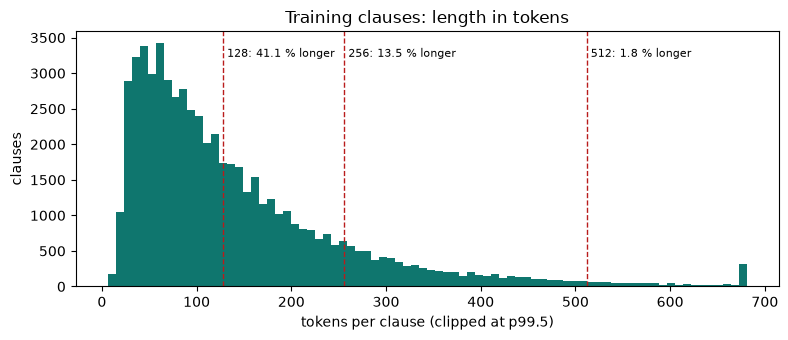

In [8]:
fig = plots.plot_length_hist(n_tokens, thresholds=(128, 256, 512), path=FIGURES / "length_hist.png")

A longer `max_length` keeps more clauses whole but costs more: self-attention is $O(T^2)$ (S05 p9) and every
batch is padded to its longest clause (S04 p6). The table counts the tokens DistilBERT processes in one epoch
(batch size 32) with random batches, and with batches of similar lengths: the sampler of
`TrainingArguments(train_sampling_strategy="group_by_length")`, which shuffles, cuts the data into
mega-batches of 50 batches and sorts each one by length. Costs are relative to 256 with random batches,
the setting of TP06.

In [9]:
candidates = pd.DataFrame(
    {
        "whole clauses": [np.mean(n_tokens <= T) for T in (128, 256, 384, 512)],
        "tokens, random": [
            data.padded_tokens(n_tokens, T, cfg.batch_size, cfg.seed) for T in (128, 256, 384, 512)
        ],
        "tokens, grouped": [
            data.padded_tokens(n_tokens, T, cfg.batch_size, cfg.seed, group_by_length=True)
            for T in (128, 256, 384, 512)
        ],
    },
    index=pd.Index([128, 256, 384, 512], name="max_length"),
)
reference = candidates.loc[256, "tokens, random"]
candidates["cost, random"] = candidates["tokens, random"] / reference
candidates["cost, grouped"] = candidates["tokens, grouped"] / reference
candidates.round(3)

,whole clauses,"tokens, random","tokens, grouped","cost, random","cost, grouped"
max_length,,,,,
128,0.589,7680000,5667392,0.500,0.369
256,0.865,15353536,7637472,1.000,0.497
384,0.951,22405824,8351040,1.459,0.544
512,0.982,27168736,8669920,1.770,0.565


Truncation is not spread evenly over the types. The ten types that would lose the most at 256 tokens, and
what they lose at `cfg.max_length`:

In [10]:
by_type = [n_tokens[train_labels == k] for k in range(cfg.n_classes)]
per_type = pd.DataFrame(
    {
        "train": counts["train"],
        "median tokens": [np.median(n) for n in by_type],
        "truncated at 256": [np.mean(n > 256) for n in by_type],
        f"truncated at {cfg.max_length}": [np.mean(n > cfg.max_length) for n in by_type],
    },
    index=LABELS,
)
per_type.sort_values("truncated at 256", ascending=False).head(10).round(2)

,train,median tokens,truncated at 256,truncated at 512
Capitalization,434,407.5,0.69,0.35
Submission To Jurisdiction,238,257.0,0.51,0.00
No Conflicts,741,248.0,0.46,0.06
Indemnity,271,239.0,0.46,0.07
Confidentiality,1012,228.0,0.46,0.09
Participations,459,246.0,0.45,0.10
Financial Statements,677,197.0,0.39,0.09
Publicity,345,197.0,0.39,0.03
Consent To Jurisdiction,175,230.0,0.38,0.02
Indemnifications,936,205.0,0.38,0.08


In [11]:
MAX_WORDS = int(np.percentile(n_words, 99))
print(f"max_words: p99 of training words = {MAX_WORDS} | Config.max_words = {cfg.max_words}")
share_truncated = np.mean(n_tokens > cfg.max_length)
print(f"max_length = {cfg.max_length}: {100 * share_truncated:.1f} % of training clauses truncated")

max_words: p99 of training words = 476 | Config.max_words = 476
max_length = 512: 1.8 % of training clauses truncated


In [12]:
assert len(n_tokens) == len(train_texts) and n_tokens.min() >= 2, "every clause has at least [CLS] and [SEP]"
assert np.mean(n_tokens >= n_words) > 0.9, "WordPiece cuts rare legal words: more tokens than words"
assert np.median(n_tokens) > 50, "contracts are longer than AG News items (median 50 tokens in TP06)"
if not cfg.fast_run:
    assert cfg.max_words == MAX_WORDS, "Config.max_words must be the measured p99 of training words"
print("Check passed ✓ lengths measured on the training split, without truncation")

Check passed ✓ lengths measured on the training split, without truncation


**What we see.** The median clause is 106 WordPiece tokens (86 words), twice an AG News item, with a long
tail: 13.5 % of training clauses exceed 256 tokens, 4.9 % exceed 384 and 1.8 % exceed 512. Truncation would hit
long, structured types first: at 256 tokens *Capitalization* loses its end in 69 % of its clauses, *Submission To
Jurisdiction*, *No Conflicts*, *Indemnity* and *Confidentiality* in about half. The cost of a longer input
depends on how batches are built. With random batches of 32, almost every batch holds one long clause and pays
for it, so 512 costs 1.77 times 256. With length-grouped batches, padding almost disappears: 512 costs 14 % more
tokens than 256, and 43 % less than 256 with random batches. Attention, the $O(T^2)$ part, is small next to the
linear layers at these lengths (about $T / 6d$, 11 % at 512 for $d = 768$).

**Decision** (`docs/DECISIONS.md`): `max_length = 512` with `train_sampling_strategy="group_by_length"`. 98.2 % of
the clauses are read whole, for less compute than the TP06 setting; the 1.8 % that are cut keep their beginning,
which is usually where the type shows. One type stays at risk: *Capitalization* (median 408 tokens) still loses
its end in 35 % of its clauses at 512, a limit to state in the model card. `max_words = 476`, the p99 in words: the LSTM reads 99 % of the clauses whole, and
packing (S04 p10) means it never pays for the padding.

# Part C: do the splits overlap?

A test clause that also appears word for word in the training set is easy for any model that memorises
(TF-IDF especially): it inflates the test score. We count exact duplicates after normalising whitespace and
case, inside each split and across splits, then list the texts that carry two different labels.

In [13]:
duplicates = data.exact_duplicates(ledgar)
duplicates

,pair,duplicates
0,train (within),920
1,validation (within),32
2,test (within),64
3,train / validation,270
4,train / test,282
5,validation / test,69


In [14]:
conflicts = data.label_conflicts(ledgar, LABELS)
conflicts

,text,labels,splits,copies
0,the failure of a party to insist upon strict adherence to any term of this agreement on an...,"[No Waivers, Waivers]","[test, train]",3
1,no delay or omission by the company in exercising any right under this agreement shall ope...,"[No Waivers, Waivers]","[test, train]",3
2,"if any provision of this amendment is held to be illegal, invalid or unenforceable, (a) th...","[Enforceability, Severability]","[test, train]",3
3,the general partner and each of the partnership entities has been duly formed and is valid...,"[Existence, Qualifications]",[train],2
4,this agreement shall be governed by and construed in accordance with the laws of the state...,"[Applicable Laws, Governing Laws]",[train],2
5,"for purposes of this section 3.01 , the term “lender” includes any l/c issuer and the term...","[Defined Terms, Terms]",[validation],2


In [15]:
overlap = duplicates.set_index("pair")["duplicates"]
if not cfg.fast_run:
    assert overlap["train / test"] < 500, "overlap below 5 % of the 10 000 test clauses: not a broken split"
    assert len(conflicts) < 20, "label conflicts are rare"
print("Check passed ✓ train / test overlap below 5 %, a handful of conflicting labels")

Check passed ✓ train / test overlap below 5 %, a handful of conflicting labels


**What we see.** 282 test clauses (2.8 %) and 270 validation clauses are exact copies of a training
clause. This is boilerplate that contracts repeat word for word (waivers, severability, governing law), not a
split we broke. We keep the official test set as it is, to stay comparable with LexGLUE, but part of the test
score rewards memorisation: the final evaluation reports the scores separately on clauses seen and not seen in
training (`data.seen_in_train`). Six texts carry two different labels, always a pair of close types (*Waivers* /
*No Waivers*, *Severability* / *Enforceability*, *Applicable Laws* / *Governing Laws*, *Terms* / *Defined
Terms*, *Existence* / *Qualifications*): for these pairs the annotation itself is ambiguous, which caps what any
model can reach on them.

# Part D: reading clauses of close types

Several type names are near-synonyms. Before any confusion matrix, we read one random training clause of each
type in the groups most likely to be confused.

In [16]:
CLOSE_TYPES = [
    ("Governing Laws", "Applicable Laws"),
    ("Indemnifications", "Indemnity"),
    ("Waivers", "No Waivers"),
    ("Terminations", "Terms"),
    ("Taxes", "Tax Withholdings", "Withholdings"),
    ("Jurisdictions", "Consent To Jurisdiction", "Submission To Jurisdiction"),
]
rng = np.random.default_rng(cfg.seed)
for group in CLOSE_TYPES:
    print("=" * 110)
    for name in group:
        i = rng.choice(np.flatnonzero(train_labels == LABELS.index(name)))
        print(f"[{name}, {counts.loc[name, 'train']} train] {train_texts[i][:320]}\n")

[Governing Laws, 3167 train] This Agreement shall be governed by and construed and enforced in accordance with the laws of the State of Delaware, as applied to contracts between Delaware residents entered into and to be performed entirely within such state without giving effect to the principles of conflicts of choice of laws of such state or any 

[Applicable Laws, 352 train] The Agreement shall be governed by and construed in accordance with the laws of the [ * ] , without regard to the conflict of law principles thereof that may dictate application of the laws of any other [ * ] , or the [ * ] as applicable.

[Indemnifications, 936 train] The Company and each Subsidiary for whom the Participant performed services as a director, officer or employee shall indemnify the Participant, to the maximum extent permitted under the Indemnification Documents.

[Indemnity, 271 train] Borrower agrees to protect, indemnify and save harmless Lender, and all directors, officers, employees and agents

**What we see.** Some groups are told apart by their wording: *Terms* is about how long an agreement or
an employment lasts, *Terminations* about how it ends; *Tax Withholdings* is about withholding on an employee's
award, *Withholdings* about an agent withholding on payments to lenders. Others are near-identical: the *Applicable
Laws* clause above is a governing-law clause in all but its label, and the three jurisdiction types all submit
the parties to a court. For these the label seems to depend on the heading the drafter chose more than on the
text: expect them to dominate the confusion matrices, and read an error inside such a group as less serious than
an error across groups.

# Part E: the floor, a lazy classifier

TP01 Ex 11: a model that always answers the most frequent training class. It learns nothing, and every
model of the project must be far above it. On LEDGAR the most frequent training class is *Governing Laws*.

In [17]:
y_val = np.array(ledgar["validation"]["label"])
lazy_val = data.lazy_baseline(train_labels, len(y_val))
lazy_metrics = {
    "accuracy": metrics.accuracy(y_val, lazy_val),
    "macro_f1": metrics.macro_f1_score(y_val, lazy_val, cfg.n_classes),
}
print(f"lazy classifier, always '{LABELS[lazy_val[0]]}', on validation:", lazy_metrics)

lazy classifier, always 'Governing Laws', on validation: {'accuracy': 0.0494, 'macro_f1': 0.0009510003792450905}


In [18]:
if not cfg.fast_run:
    assert LABELS[lazy_val[0]] == "Governing Laws", "the most frequent training type"
assert lazy_metrics["macro_f1"] < 0.01, "one type found out of 99: macro-F1 close to 0"
print("Check passed ✓ the floor: macro-F1 close to 0")

Check passed ✓ the floor: macro-F1 close to 0


**What we see.** Always answering *Governing Laws* gives 4.9 % accuracy and a macro-F1 of 0.001 on
validation. Unlike the 90 % of the lazy classifier of TP01, the accuracy is low too: even the largest type holds
only 5 % of the clauses. On LEDGAR the trap is not a high accuracy for a useless model, it is a model that does
well on the twenty boilerplate types and ignores the long tail, and macro-F1 is the number that shows it. This
floor is the first row of the results table.

## Save the artefacts

The class counts and the length study go to `reports/`; the lazy classifier is saved as a run like any other
model. Its test predictions are written here, once: it has no hyperparameter, so nothing can be tuned on them.

In [19]:
reports = cfg.path(cfg.reports_dir)
reports.mkdir(parents=True, exist_ok=True)
counts.to_csv(reports / "class_counts.csv", index_label="label")
summary = {
    "class_stats": class_stats,
    "words": data.length_stats(n_words),
    "max_words_p99": MAX_WORDS,
    "wordpiece": data.length_stats(n_tokens, thresholds=(128, 256, 384, 512)),
    "max_length_candidates": candidates.round(4).reset_index().to_dict(orient="records"),
    "duplicates": overlap.to_dict(),
    "label_conflicts": len(conflicts),
}
(reports / "data_summary.json").write_text(json.dumps(summary, indent=2) + "\n")
print("written:", sorted(p.name for p in reports.iterdir()))

written: ['class_counts.csv', 'data_summary.json', 'figures']


In [20]:
run_dir = cfg.path(cfg.out_dir, "lazy")
val_index = ledgar["validation"]["index"]
runs.save_predictions(run_dir, "val", y_val, lazy_val, index=val_index, label_names=LABELS)
runs.save_run(run_dir, cfg, {"model": "lazy", "trainable_params": 0, "val": lazy_metrics}, duration_s=0.0)
print("run saved to", run_dir.relative_to(cfg.path()))

run saved to results/lazy


In [21]:
y_test = np.array(ledgar["test"]["label"])  # predict & save: the test split, used once
lazy_test = data.lazy_baseline(train_labels, len(y_test))
runs.save_predictions(run_dir, "test", y_test, lazy_test, index=ledgar["test"]["index"], label_names=LABELS)
test_metrics = {
    "accuracy": metrics.accuracy(y_test, lazy_test),
    "macro_f1": metrics.macro_f1_score(y_test, lazy_test, cfg.n_classes),
}
runs.save_run(run_dir, cfg, {"test": test_metrics})
print("written:", sorted(p.name for p in run_dir.iterdir()), "| missing:", runs.missing_files(run_dir))

written: ['config.json', 'log_history.json', 'manifest.json', 'metrics.json', 'pred_test.csv', 'pred_test.npz', 'pred_val.csv', 'pred_val.npz'] | missing: []


Next: `02_baseline_tfidf.ipynb`, the TF-IDF + logistic-regression baseline (checkpoint m1).